✅ Simulation 03 completed successfully!
📁 High-resolution figure saved at: figures/sim03_non_orthogonality_overcompleteness.png


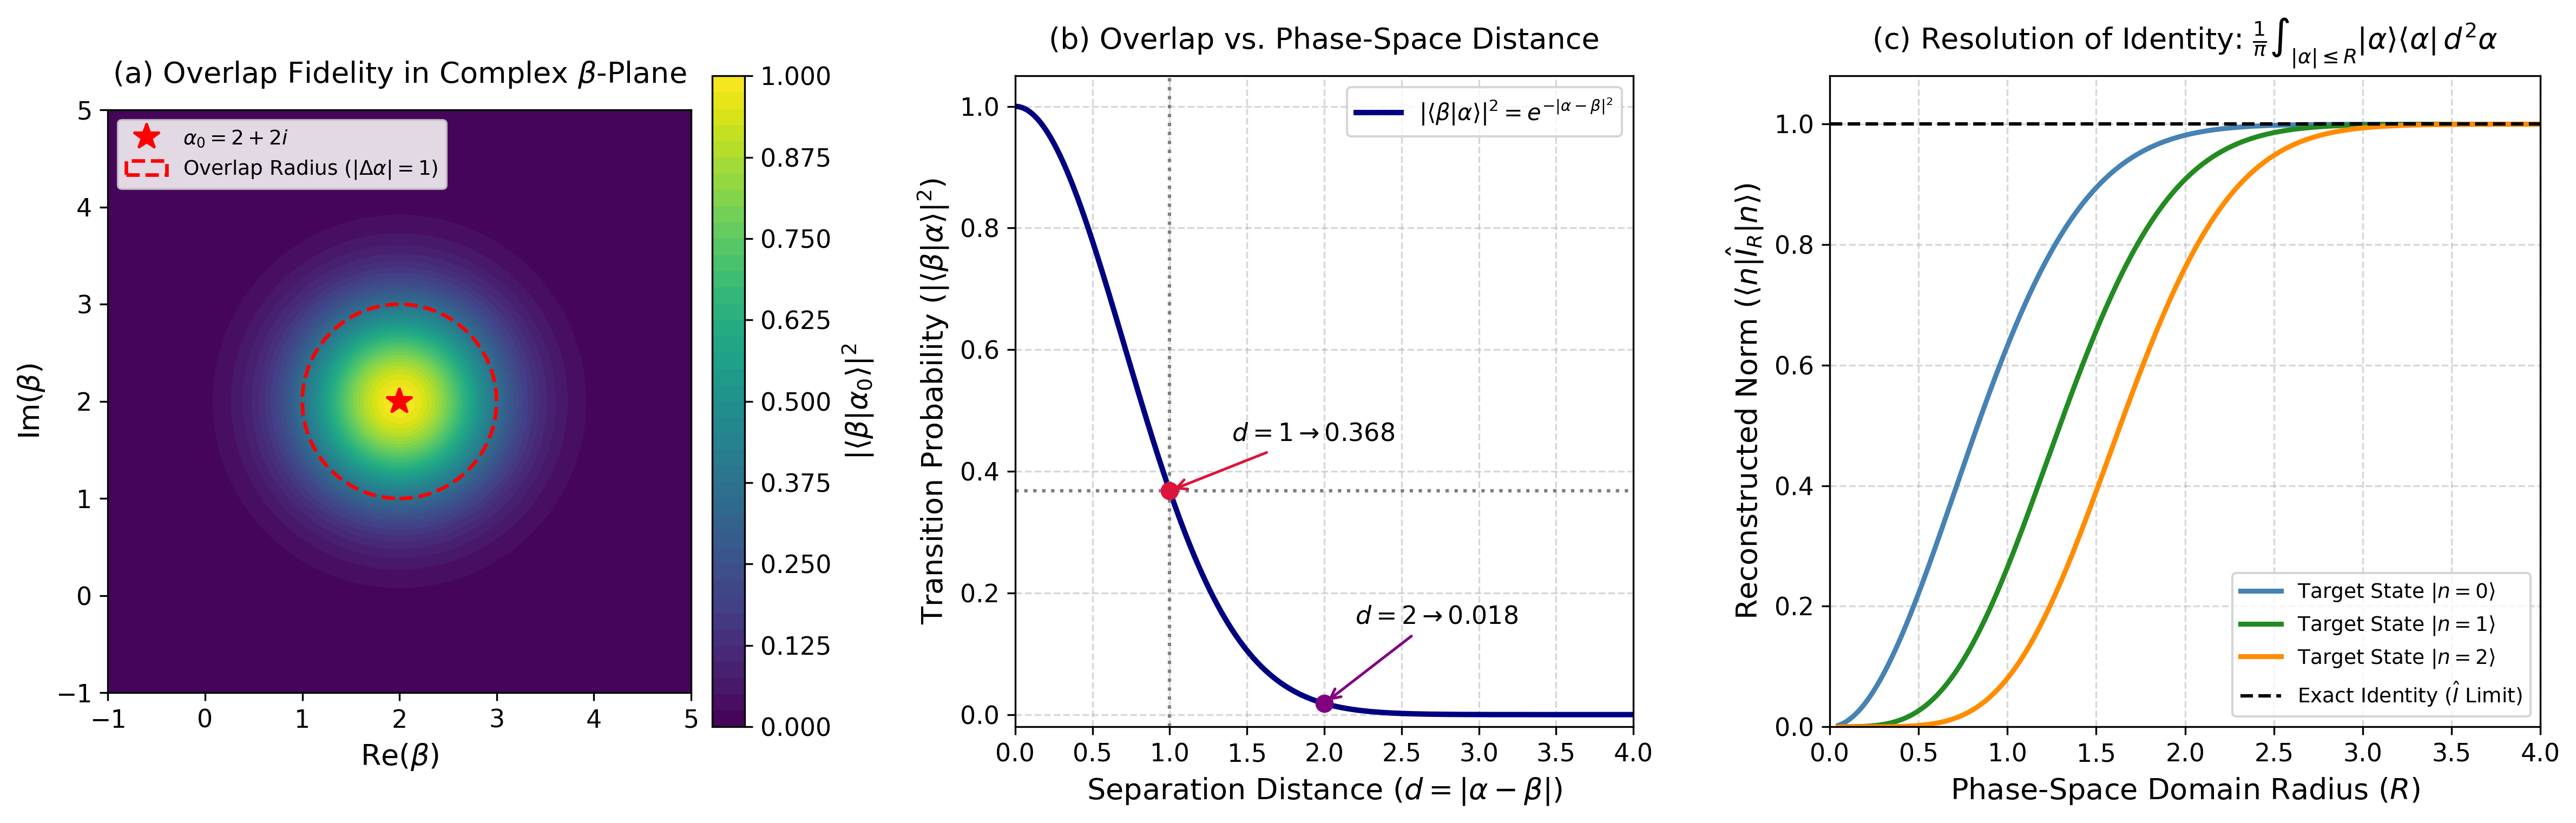

In [7]:
"""
===============================================================================
Computational Quantum Optics: Gerry & Knight Simulations
Chapter 03: Coherent States of Light
Simulation 03: Quantum Non-Orthogonality & Overcompleteness in Phase Space
===============================================================================

Reference:
    "Introductory Quantum Optics", Christopher C. Gerry & Sir Peter L. Knight,
    Chapter 3, Section 3.2: Properties of Coherent States.

Description:
    Demonstrates that coherent states are non-orthogonal (|⟨β|α⟩|² = exp(-|α - β|²))
    and form an overcomplete basis. Computes the 2D phase-space overlap profile, 
    the rapid exponential decay of state overlap with distance, and numerically 
    verifies the resolution of identity (1/pi * ∫ |α⟩⟨α| d²α = I) by integrating 
    projectors of Fock states over circular phase-space domains of radius R.
"""

import os
import math
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. Aesthetics & Plot Setup
# -----------------------------------------------------------------------------
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 13,
    'axes.titlesize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 10,
    'figure.titlesize': 15,
    'text.usetex': False  # Fully compatible with Kaggle mathtext engine
})

# -----------------------------------------------------------------------------
# 2. Mathematical & Physical Formulations
# -----------------------------------------------------------------------------
# (a) 2D Overlap in Phase Space for a Reference State alpha_0
alpha_0 = 2.0 + 2.0j
x_vals = np.linspace(-1.0, 5.0, 400)
y_vals = np.linspace(-1.0, 5.0, 400)
X, Y = np.meshgrid(x_vals, y_vals)
Beta = X + 1j * Y

# Transition probability (Fidelity): |⟨β|α₀⟩|² = exp(-|β - α₀|²)
overlap_2d = np.exp(-np.abs(Beta - alpha_0)**2)

# (b) Overlap vs. Euclidean Separation Distance d = |α - β|
distance = np.linspace(0.0, 4.0, 500)
overlap_1d = np.exp(-distance**2)

# (c) Numerical Verification of Resolution of Identity:
# Projecting |n⟩ onto the coherent basis:
# (1 / pi) * ∫_{|α| <= R} |⟨α|n⟩|² d²α = 1 - exp(-R²) * ∑_{k=0}^n (R^(2k) / k!)
R_vals = np.linspace(0.05, 4.0, 400)

def identity_convergence(n, R):
    """Calculates the completeness integral as a function of phase-space radius R."""
    sum_terms = np.zeros_like(R)
    for k in range(n + 1):
        factorial_k = float(math.factorial(k))
        sum_terms += (R**(2 * k)) / factorial_k
    return 1.0 - np.exp(-R**2) * sum_terms

conv_n0 = identity_convergence(0, R_vals)  # Vacuum state |0⟩
conv_n1 = identity_convergence(1, R_vals)  # Fock state |1⟩
conv_n2 = identity_convergence(2, R_vals)  # Fock state |2⟩

# -----------------------------------------------------------------------------
# 3. Multi-Panel Figure Layout
# -----------------------------------------------------------------------------
fig = plt.figure(figsize=(16, 5.2), dpi=300)
gs = fig.add_gridspec(1, 3, width_ratios=[1.15, 1.0, 1.15])

# --- Subplot (a): 2D Overlap Contour in Phase Space ---
ax1 = fig.add_subplot(gs[0, 0])
c = ax1.contourf(X, Y, overlap_2d, levels=40, cmap='viridis')
cbar = fig.colorbar(c, ax=ax1, pad=0.03)
cbar.set_label(r'$|\langle \beta | \alpha_0 \rangle|^2$', rotation=90)

# Reference center and uncertainty boundary (radius = 1)
ax1.plot(alpha_0.real, alpha_0.imag, 'r*', markersize=12, label=r'$\alpha_0 = 2 + 2i$')
circle = plt.Circle((alpha_0.real, alpha_0.imag), 1.0, color='red', fill=False, 
                    linestyle='--', lw=1.6, label=r'Overlap Radius ($|\Delta \alpha| = 1$)')
ax1.add_patch(circle)

ax1.set_title(r'(a) Overlap Fidelity in Complex $\beta$-Plane', pad=12)
ax1.set_xlabel(r'Re($\beta$)')
ax1.set_ylabel(r'Im($\beta$)')
ax1.set_aspect('equal')
ax1.legend(loc='upper left', frameon=True, framealpha=0.85, fontsize=9)

# --- Subplot (b): Exponential Decay of Overlap Fidelity ---
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(distance, overlap_1d, color='navy', lw=2.4, label=r'$|\langle \beta | \alpha \rangle|^2 = e^{-|\alpha - \beta|^2}$')
ax2.axvline(1.0, color='gray', linestyle=':', lw=1.5)
ax2.axhline(np.exp(-1.0), color='gray', linestyle=':', lw=1.5)

# Highlighting significant points
ax2.scatter([1.0], [np.exp(-1.0)], color='crimson', s=50, zorder=5)
ax2.annotate(rf'$d = 1 \rightarrow {np.exp(-1):.3f}$', xy=(1.0, np.exp(-1.0)), 
             xytext=(1.4, 0.45), arrowprops=dict(arrowstyle="->", color='crimson', lw=1.2))

ax2.scatter([2.0], [np.exp(-4.0)], color='purple', s=50, zorder=5)
ax2.annotate(rf'$d = 2 \rightarrow {np.exp(-4):.3f}$', xy=(2.0, np.exp(-4.0)), 
             xytext=(2.2, 0.15), arrowprops=dict(arrowstyle="->", color='purple', lw=1.2))

ax2.set_title(r'(b) Overlap vs. Phase-Space Distance', pad=12)
ax2.set_xlabel(r'Separation Distance ($d = |\alpha - \beta|$)')
ax2.set_ylabel(r'Transition Probability ($|\langle \beta | \alpha \rangle|^2$)')
ax2.set_xlim([0, 4])
ax2.set_ylim([-0.02, 1.05])
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right', frameon=True)

# --- Subplot (c): Completeness Relation Convergence ---
ax3 = fig.add_subplot(gs[0, 2])
ax3.plot(R_vals, conv_n0, color='steelblue', lw=2.2, label=r'Target State $|n = 0\rangle$')
ax3.plot(R_vals, conv_n1, color='forestgreen', lw=2.2, label=r'Target State $|n = 1\rangle$')
ax3.plot(R_vals, conv_n2, color='darkorange', lw=2.2, label=r'Target State $|n = 2\rangle$')

ax3.axhline(1.0, color='black', linestyle='--', lw=1.5, label=r'Exact Identity ($\hat{I}$ Limit)')

# Note: Using \leq instead of \le for full mathtext parser compatibility
ax3.set_title(r'(c) Resolution of Identity: $\frac{1}{\pi} \int_{|\alpha| \leq R} |\alpha\rangle\langle\alpha| \, d^2\alpha$', pad=12)
ax3.set_xlabel(r'Phase-Space Domain Radius ($R$)')
ax3.set_ylabel(r'Reconstructed Norm ($\langle n|\hat{I}_R|n\rangle$)')
ax3.set_xlim([0, 4])
ax3.set_ylim([0, 1.08])
ax3.grid(True, linestyle='--', alpha=0.5)
ax3.legend(loc='lower right', frameon=True, fontsize=9)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 4. Save and Export
# -----------------------------------------------------------------------------
os.makedirs("figures", exist_ok=True)
output_path = os.path.join("figures", "sim03_non_orthogonality_overcompleteness.png")
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"✅ Simulation 03 completed successfully!")
print(f"📁 High-resolution figure saved at: {output_path}")

plt.show()